|--- RM <= 6.80
|   |--- LSTAT <= 14.40
|   |   |--- value: [22.98]
|   |--- LSTAT >  14.40
|   |   |--- value: [14.81]
|--- RM >  6.80
|   |--- RM <= 7.43
|   |   |--- value: [30.92]
|   |--- RM >  7.43
|   |   |--- value: [44.71]



[Text(167.4, 181.2, 'node #0\nRM <= 6.8\nmse = 84.76\nsamples = 354\nvalue = 22.75'),
 Text(83.7, 108.72, 'node #1\nLSTAT <= 14.4\nmse = 35.01\nsamples = 284\nvalue = 19.61'),
 Text(41.85, 36.23999999999998, 'node #2\nmse = 20.78\nsamples = 167\nvalue = 22.98'),
 Text(125.55000000000001, 36.23999999999998, 'node #3\nmse = 16.05\nsamples = 117\nvalue = 14.81'),
 Text(251.10000000000002, 108.72, 'node #4\nRM <= 7.43\nmse = 85.39\nsamples = 70\nvalue = 35.45'),
 Text(209.25, 36.23999999999998, 'node #5\nmse = 44.15\nsamples = 47\nvalue = 30.92'),
 Text(292.95, 36.23999999999998, 'node #6\nmse = 42.03\nsamples = 23\nvalue = 44.71')]

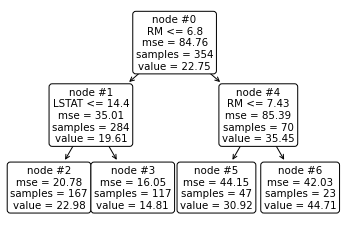

In [1]:
### boston房价预测--决策树

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor,export_text
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import cohen_kappa_score

# Data Preparation

data = pd.read_csv('boston_housing_data.csv').rename(columns={'PIRATIO': 'PTRATIO'})
X = data.drop(columns='MEDV')
y = data['MEDV']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# Regression Tree 

model = DecisionTreeRegressor(max_depth=2, random_state=123)
model.fit(X_train, y_train)
model.score(X_test, y_test)

print(export_text(model, feature_names=list(X.columns)))

plot_tree(model, feature_names=X.columns, node_ids=True, rounded=True, precision=2)


{'ccp_alpha': 0.03671186440677543,
 'criterion': 'mse',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_impurity_split': None,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'random_state': 123,
 'splitter': 'best'}

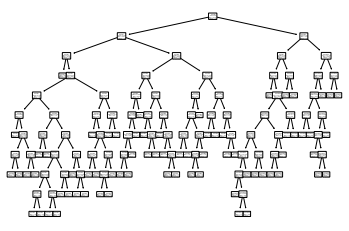

In [2]:
# Graph total impurities versus ccp_alphas 

model = DecisionTreeRegressor(random_state=123)
path = model.cost_complexity_pruning_path(X_train, y_train)

plt.plot(path.ccp_alphas, path.impurities, marker='o', drawstyle='steps-post')
plt.xlabel('alpha (cost-complexity parameter)')
plt.ylabel('Total Leaf MSE')
plt.title('Total Leaf MSE vs alpha for Training Set')

max(path.ccp_alphas),  max(path.impurities)

# Choose optimal ccp_alpha via CV

param_grid = {'ccp_alpha': path.ccp_alphas} 
kfold = KFold(n_splits=10, shuffle=True, random_state=1)
model = GridSearchCV(DecisionTreeRegressor(random_state=123), param_grid, cv=kfold)
model.fit(X_train, y_train)

model.best_params_
model = model.best_estimator_
model.score(X_test,y_test)

plot_tree(model, feature_names=X.columns, node_ids=True, rounded=True, precision=2)

model.get_depth()
model.get_n_leaves()
model.get_params()

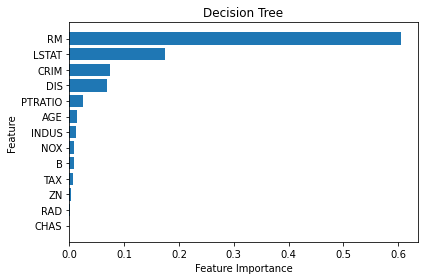

In [3]:
# Visualize Feature Importance
          
model.feature_importances_

sorted_index = model.feature_importances_.argsort()
sorted_index 

plt.barh(range(X.shape[1]), model.feature_importances_[sorted_index])
plt.yticks(np.arange(X.shape[1]), X.columns[sorted_index])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Decision Tree')
plt.tight_layout()